
### Library dan dependency



In [ ]:
%pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 8.2 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=a5efc9cd1f95da730406c4cb535fb82f783926ddea7fd7705fd7af7debe47f3e
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import restricted_mean_survival_time

### EDA

In [ ]:
df = pd.read_csv('/content/aids_clinical_trials_175.csv')
# time = waktu survival, cid = event/sensor, trt = jenis pengobatan, cd40 = imun awal
df_study = df[['time', 'cid', 'trt', 'cd40']].copy()

print(f"Total observasi: {len(df_study)} pasien")
print(df_study.head())
print("-" * 50)

Total observasi: 2139 pasien
   time  cid  trt  cd40
0   948    0    2   422
1  1002    1    3   162
2   961    0    3   326
3  1166    0    3   287
4  1090    0    0   504
--------------------------------------------------


In [ ]:
# Distribusi Pasien per Grup Terapi
print("Jumlah Pasien Berdasarkan Regimen Terapi (trt):")
obat_labels = {0: 'ZDV only', 1: 'ZDV + ddI', 2: 'ZDV + Zal', 3: 'ddI only'}
print(df_study['trt'].map(obat_labels).value_counts())

Jumlah Pasien Berdasarkan Regimen Terapi (trt):
trt
ddI only     561
ZDV only     532
ZDV + Zal    524
ZDV + ddI    522
Name: count, dtype: int64


/tmp/ipykernel_1459/4090248450.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_study, x='cid', palette='Set2')


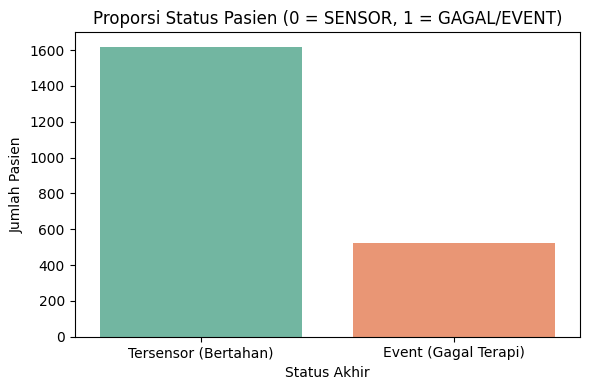

--------------------------------------------------


In [ ]:
# Visualisasi Status Akhir Pasien
plt.figure(figsize=(6, 4))
sns.countplot(data=df_study, x='cid', palette='Set2')
plt.title('Proporsi Status Pasien (0 = SENSOR, 1 = GAGAL/EVENT)')
plt.xlabel('Status Akhir')
plt.ylabel('Jumlah Pasien')
plt.xticks([0, 1], ['Tersensor (Bertahan)', 'Event (Gagal Terapi)'])
plt.tight_layout()
plt.show()
print("-" * 50)

### KM dan Log-Rank


--- KAPLAN-MEIER & LOG-RANK ---


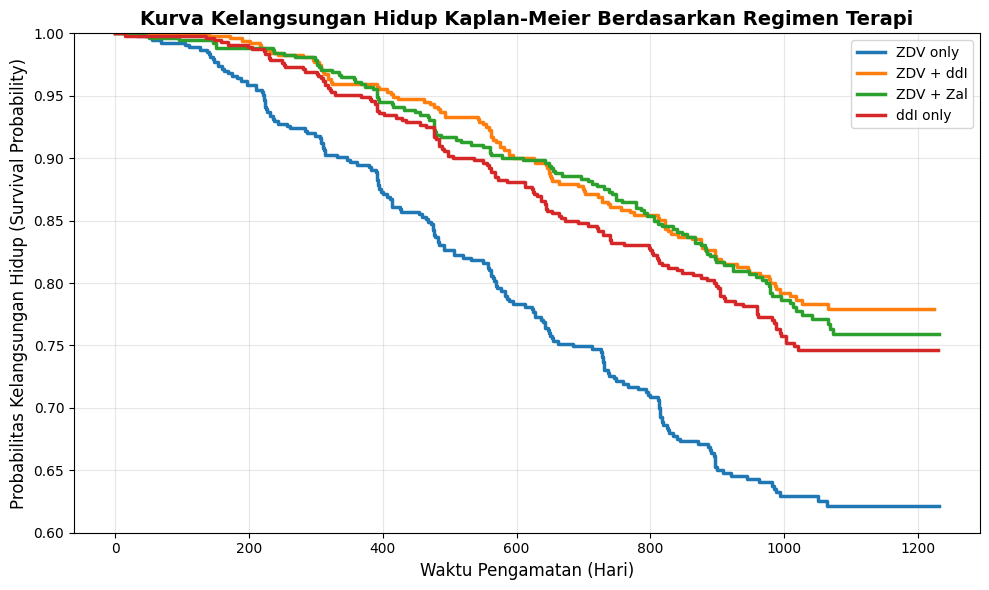

In [ ]:
print("\n--- KAPLAN-MEIER & LOG-RANK ---")

# Plot Kurva Kaplan-Meier
plt.figure(figsize=(10, 6))
kmf = KaplanMeierFitter()

for i in range(4):
    grup = df_study[df_study['trt'] == i]
    kmf.fit(durations=grup['time'], event_observed=grup['cid'], label=obat_labels[i])
    kmf.plot_survival_function(ci_show=False, linewidth=2.5)

plt.title('Kurva Kelangsungan Hidup Kaplan-Meier Berdasarkan Regimen Terapi', fontsize=14, fontweight='bold')
plt.xlabel('Waktu Pengamatan (Hari)', fontsize=12)
plt.ylabel('Probabilitas Kelangsungan Hidup (Survival Probability)', fontsize=12)
plt.grid(alpha=0.3)
plt.ylim(0.6, 1.0)
plt.tight_layout()
plt.savefig('kurva_kaplan_meier.png', dpi=300)
plt.show()

In [ ]:
# Uji Hipotesis dengan LOG-RANK TEST
# Menguji apakah perbedaan ke-4 kurva di atas signifikan secara statistik
print("\n[UJI HIPOTESIS] Hasil Multivariate Log-Rank Test:")
hasil_logrank = multivariate_logrank_test(df_study['time'], df_study['trt'], df_study['cid'])
print(f"Chi-squared: {hasil_logrank.test_statistic:.4f}")
print(f"p-value    : {hasil_logrank.p_value:.4f}")

if hasil_logrank.p_value < 0.05:
    print("Kesimpulan : H0 Ditolak. Terdapat perbedaan signifikan dalam kelangsungan hidup antar kelompok terapi.")
else:
    print("Kesimpulan : Gagal Tolak H0. Tidak terdapat perbedaan signifikan antar kelompok terapi.")
print("-" * 50)


[UJI HIPOTESIS] Hasil Multivariate Log-Rank Test:
Chi-squared: 49.1941
p-value    : 0.0000
Kesimpulan : H0 Ditolak. Terdapat perbedaan signifikan dalam kelangsungan hidup antar kelompok terapi.
--------------------------------------------------


### Cek PH

In [ ]:
print("\n--- PEMODELAN COX PROPORTIONAL HAZARDS ---")
cph = CoxPHFitter()
# Memasukkan CD40 sebagai variabel kontrol imun awal pasien
cph.fit(df_study, duration_col='time', event_col='cid', formula="C(trt) + cd40")
cph.print_summary()


--- PEMODELAN COX PROPORTIONAL HAZARDS ---


<lifelines.CoxPHFitter: fitted with 2139 total observations, 1618 right-censored observations>
             duration col = 'time'
                event col = 'cid'
      baseline estimation = breslow
   number of observations = 2139
number of events observed = 521
   partial log-likelihood = -3792.44
         time fit was run = 2026-06-07 09:34:52 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
C(trt)[T.1] -0.79      0.46      0.12           -1.03           -0.54                0.36                0.58
C(trt)[T.2] -0.68      0.51      0.12           -0.92           -0.44                0.40                0.64
C(trt)[T.3] -0.58      0.56      0.12           -0.81           -0.36                0.44                0.70
cd40        -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00

             cmp to     z      p  -log2(p)
covariate                                 
C(trt)[T.1]    0.00 -6.34 <0.005     31.99
C(trt)[T.2]    0.00 -5.62 <0.005     25.63
C(trt)[T.3]    0.00 -5.05 <0.005     21.08
cd40           0.00 -9.72 <0.005     71.73
---
Concordance = 0.66
Partial AIC = 7592.89
log-likelihood ratio test = 146.52 on 4 df
-log2(p) of ll-ratio test = 99.48


[UJI ASUMSI] Memeriksa Asumsi Proportional Hazards:

   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'C(trt)[T.1]' failed the non-proportional test: p-value is 0.0126.

   Advice: with so few unique values (only 2), you can include `strata=['C(trt)[T.1]', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


2. Variable 'C(trt)[T.2]' failed the non-proportional test: p-value is 0.0065.

   Advice: with so few unique values (only 2), you can include `strata=['C(trt)[T.2]', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


3. Variable 'cd40' failed the non-proportional test: p-value is 0.0001.

   Advice 1: the functional form of the variable 'cd40' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: t

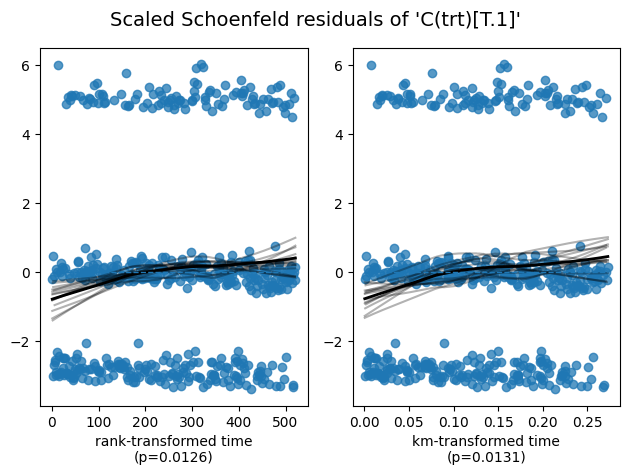

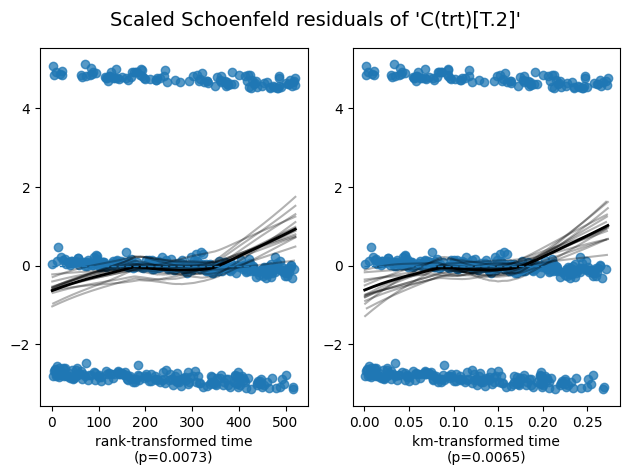

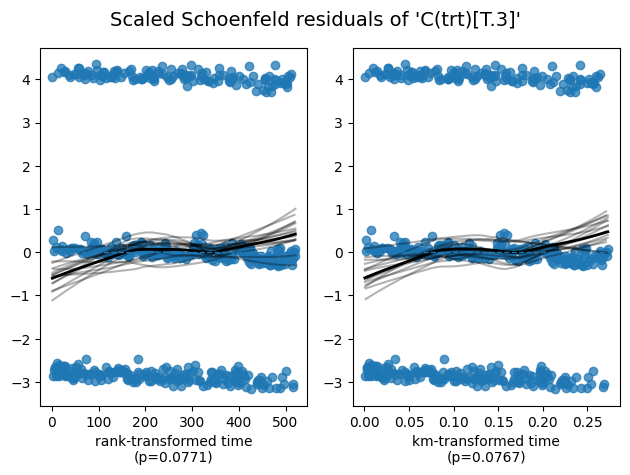

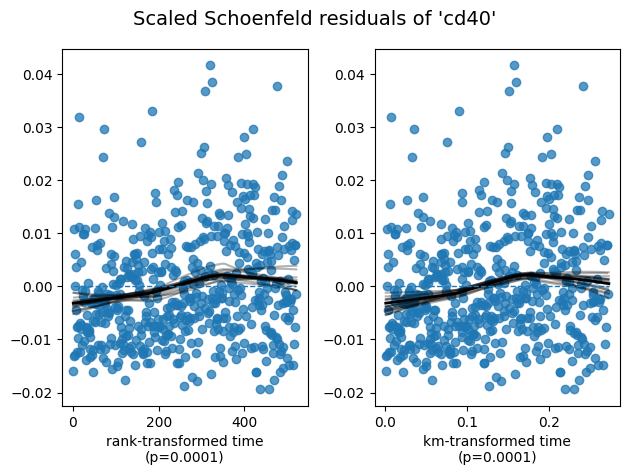

--------------------------------------------------


In [ ]:
# Uji Asumsi Proportional Hazards (Schoenfeld Residuals)
print("\n[UJI ASUMSI] Memeriksa Asumsi Proportional Hazards:")
cph.check_assumptions(df_study, p_value_threshold=0.05, show_plots=True)
plt.tight_layout()
plt.show()
print("-" * 50)

### Cek AFT

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from lifelines import NelsonAalenFitter
from lifelines import WeibullAFTFitter, LogNormalAFTFitter, LogLogisticAFTFitter

# --- 1. ADU AIC DAN BIC KETIGA DISTRIBUSI ---
print("--- UJI ASUMSI KESESUAIAN DISTRIBUSI (GOODNESS OF FIT) ---")
# Fit ketiga model
aft_weibull = WeibullAFTFitter().fit(df_study, duration_col='time', event_col='cid', formula="C(trt) + cd40")
aft_ln = LogNormalAFTFitter().fit(df_study, duration_col='time', event_col='cid', formula="C(trt) + cd40")
aft_ll = LogLogisticAFTFitter().fit(df_study, duration_col='time', event_col='cid', formula="C(trt) + cd40")

# Menampilkan perbandingan AIC dan BIC
# (Ingat: Semakin kecil nilainya, semakin baik modelnya)
print(f"{'Model':<15} | {'AIC':<10} | {'BIC':<10}")
print("-" * 40)
print(f"{'Weibull':<15} | {aft_weibull.AIC_:<10.2f} | {aft_weibull.BIC_:<10.2f}")
print(f"{'Log-Normal':<15} | {aft_ln.AIC_:<10.2f} | {aft_ln.BIC_:<10.2f}")
print(f"{'Log-Logistic':<15} | {aft_ll.AIC_:<10.2f} | {aft_ll.BIC_:<10.2f}")


--- UJI ASUMSI KESESUAIAN DISTRIBUSI (GOODNESS OF FIT) ---
Model           | AIC        | BIC       
----------------------------------------
Weibull         | 9349.88    | 9353.21   
Log-Normal      | 9323.08    | 9326.42   
Log-Logistic    | 9334.39    | 9337.73   


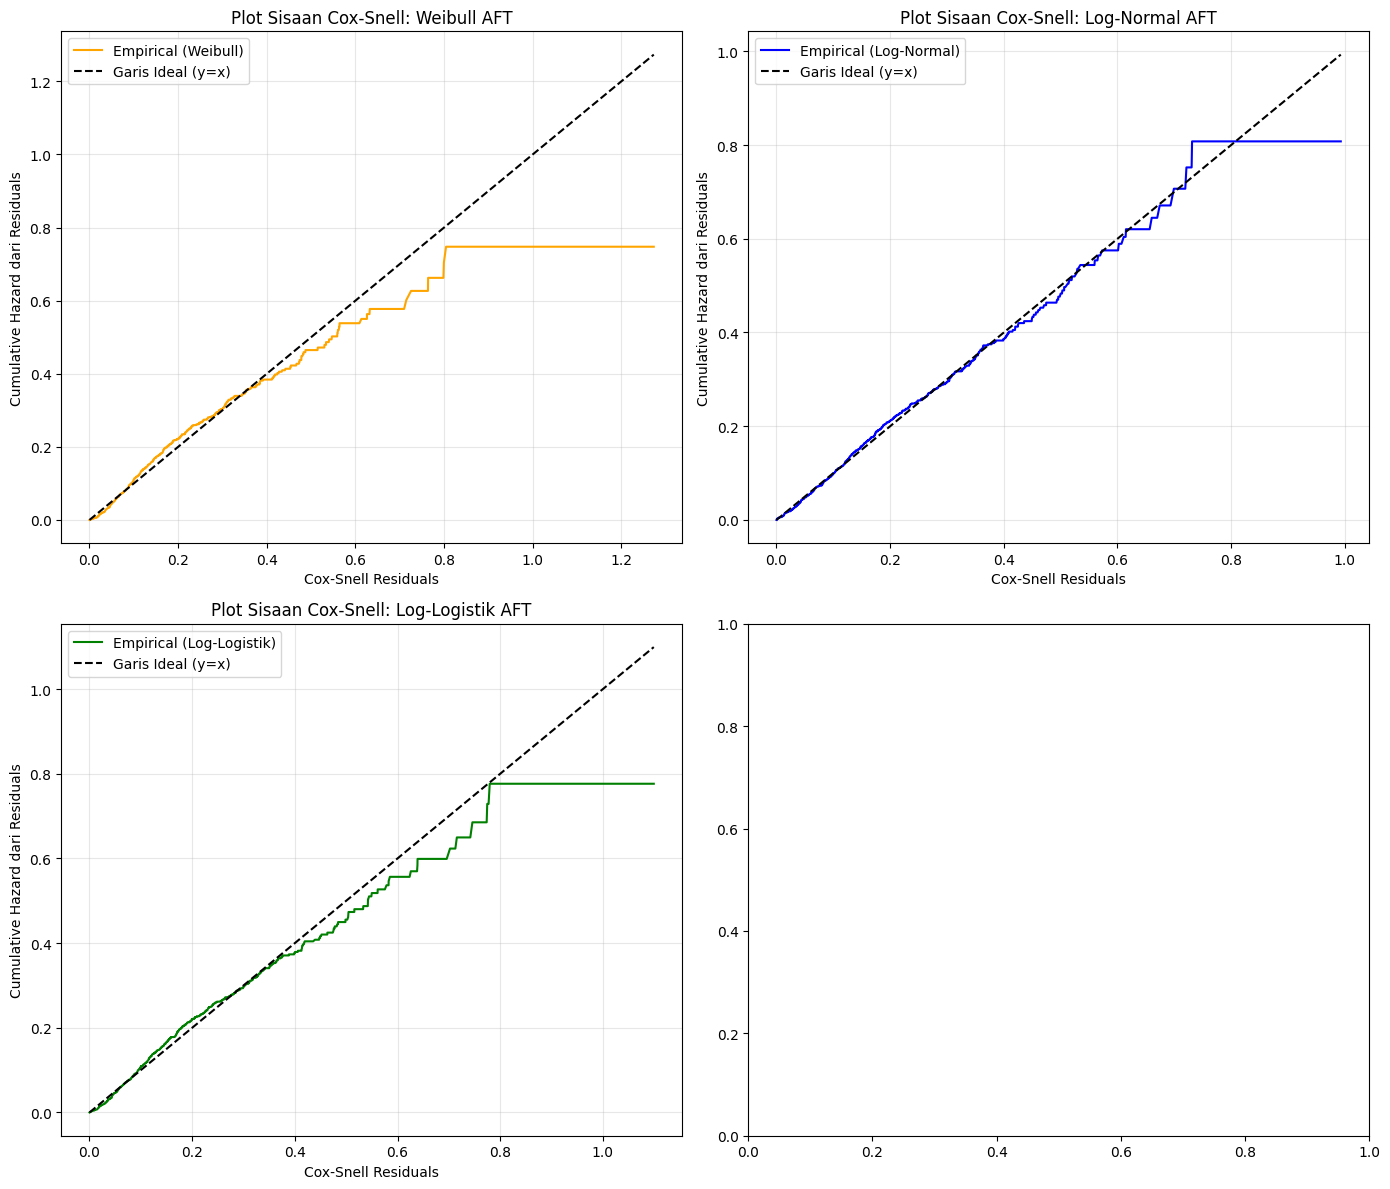

In [ ]:
T = df_study['time']
E = df_study['cid']

# Buat list untuk iterasi biar kodenya rapi dan nggak ngulang-ngulang
models = [
    ('Weibull', aft_weibull, 'orange'),
    ('Log-Normal', aft_ln, 'blue'),
    ('Log-Logistik', aft_ll, 'green')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten() # Meratakan array axis biar gampang di-loop

for i, (name, model, color) in enumerate(models):
    # Prediksi fungsi survival untuk tiap pasien
    S_pred = model.predict_survival_function(df_study, times=T)
    S_diag = np.diag(S_pred.values)

    # Hitung sisaan Cox-Snell
    cs_residuals = -np.log(S_diag)

    # Fitting Nelson-Aalen
    naf = NelsonAalenFitter()
    naf.fit(cs_residuals, event_observed=E)

    # Plotting
    axes[i].plot(naf.cumulative_hazard_.index, naf.cumulative_hazard_.values,
                 label=f'Empirical ({name})', color=color)
    max_val = cs_residuals.max()
    axes[i].plot([0, max_val], [0, max_val], 'k--', label='Garis Ideal (y=x)')

    axes[i].set_title(f'Plot Sisaan Cox-Snell: {name} AFT')
    axes[i].set_xlabel('Cox-Snell Residuals')
    axes[i].set_ylabel('Cumulative Hazard dari Residuals')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Log Normal AFT

In [ ]:
from lifelines import LogNormalAFTFitter

In [ ]:
# Menggunakan Log-Normal AFT yang bebas dari asumsi Proportional Hazards
aft_ln = LogNormalAFTFitter()
aft_ln.fit(df_study, duration_col='time', event_col='cid', formula="C(trt) + cd40")

# Menampilkan ringkasan model
aft_ln.print_summary()

<lifelines.LogNormalAFTFitter: fitted with 2139 total observations, 1618 right-censored observations>
             duration col = 'time'
                event col = 'cid'
   number of observations = 2139
number of events observed = 521
           log-likelihood = -4655.54
         time fit was run = 2026-06-07 09:35:06 UTC

---
                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param  covariate                                                                                                    
mu_    Intercept    6.27    526.07      0.11            6.04            6.49              421.52              656.55
       C(trt)[T.1]  0.60      1.82      0.09            0.42            0.77                1.52                2.17
       C(trt)[T.2]  0.54      1.72      0.09            0.37            0.72                1.44                2.04
       C(trt)[T.3]  0.46      1.58      0.09            0.29            0.63                1.34                1.87
       cd40         0.00      1.00      0.00            0.00            0.00                1.00                1.00
sigma_ Intercept    0.09      1.09      0.04            0.02            0.16                1.02                1.17

                    cmp to     z      p  -log2(p)
param  covariate                                 
mu_    Intercept      0.00 55.42 <0.005       inf
       C(trt)[T.1]    0.00  6.66 <0.005     35.06
       C(trt)[T.2]    0.00  6.07 <0.005     29.58
       C(trt)[T.3]    0.00  5.35 <0.005     23.41
       cd40           0.00  9.98 <0.005     75.51
sigma_ Intercept      0.00  2.50   0.01      6.34
---
Concordance = 0.66
AIC = 9323.08
log-likelihood ratio test = 161.66 on 4 df
-log2(p) of ll-ratio test = 110.26

In [ ]:
print("\n[INTERPRETASI TIME RATIO (TR)]")
for covariate in aft_ln.params_.index:
    # Mengambil nilai koefisien (beta) dari parameter mu_ (lokasi waktu)
    if covariate[0] == 'mu_':
        nama_variabel = covariate[1]
        koefisien = aft_ln.params_[covariate]
        time_ratio = np.exp(koefisien)
        print(f"Variabel {nama_variabel}: Time Ratio = {time_ratio:.3f}")
print("-" * 50)


[INTERPRETASI TIME RATIO (TR)]
Variabel Intercept: Time Ratio = 526.071
Variabel C(trt)[T.1]: Time Ratio = 1.817
Variabel C(trt)[T.2]: Time Ratio = 1.717
Variabel C(trt)[T.3]: Time Ratio = 1.581
Variabel cd40: Time Ratio = 1.003
--------------------------------------------------


### RMST

In [ ]:
# RMST
print("\n---  RESTRICTED MEAN SURVIVAL TIME (RMST) ---")
# Menetapkan batas waktu pengamatan (t* = 1000 hari)
t_star = 1000
print(f"Menghitung rata-rata waktu bertahan (hari sehat) pasien hingga hari ke-{t_star}:")

for i in range(4):
    grup = df_study[df_study['trt'] == i]
    kmf_rmst = KaplanMeierFitter()
    kmf_rmst.fit(durations=grup['time'], event_observed=grup['cid'])

    # Menghitung nilai RMST berdasarkan area di bawah kurva
    rmst_val = restricted_mean_survival_time(kmf_rmst.survival_function_, t=t_star)
    print(f" * Kelompok Terapi '{obat_labels[i]}': Rata-rata bertahan {rmst_val:.2f} hari")


---  RESTRICTED MEAN SURVIVAL TIME (RMST) ---
Menghitung rata-rata waktu bertahan (hari sehat) pasien hingga hari ke-1000:
 * Kelompok Terapi 'ZDV only': Rata-rata bertahan 827.12 hari
 * Kelompok Terapi 'ZDV + ddI': Rata-rata bertahan 919.64 hari
 * Kelompok Terapi 'ZDV + Zal': Rata-rata bertahan 917.78 hari
 * Kelompok Terapi 'ddI only': Rata-rata bertahan 902.06 hari


/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:263: ApproximationWarning: Approximating RMST using the precomputed survival function. You likely will get a more accurate estimate if you provide the fitted Model instead of the survival function.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:263: ApproximationWarning: Approximating RMST using the precomputed survival function. You likely will get a more accurate estimate if you provide the fitted Model instead of the survival function.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:263: ApproximationWarning: Approximating RMST using the precomputed survival function. You likely will get a more accurate estimate if you provide the fitted Model instead of the survival function.

  warnings.warn(
/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:263: ApproximationWarning: Approximating RMST using the precomputed survival fun